# 1. Introduction

The **two-dimensional sound field analysis** problem is a forward problem in which the measured sound pressure is the superposition of propagating plane waves. The sound field at a given angular frequency, $\omega$ [rad/s], and location $\mathbf{r}_{\text{m}} = (x_{\text{m}}, z_{\text{m}})$ [m] is described by

\begin{equation}
    \tilde{p}(\mathbf{r}_{\text{m}}, \omega) 
    = \sum\limits_{i=1}^{N} \tilde{x}_i \exp(\text{-j} \mathbf{k}_i \cdot \mathbf{r}_{\text{m}}),
\tag{1}
\end{equation}

where $\mathbf{k}_i = (k_{x_i}, k_{z_i})$ is the $ i$-th plane-wave wave-number vector, with norm $\|\mathbf{k}_i\|_2 = \frac{\omega}{c_0}=k_0$, and $N$ is the number of plane waves in the sound field; you will note that we can have either just a few plane waves (sparse solution) or a somewhat continuous distribution of plane waves. The problem is restricted to propagating plane waves, which satisfy the condition:

\begin{equation}
    \|\mathbf{k}_i\|_2^2 = k_{x}^2 + k_{z}^2 = k_0^2.
\tag{2}
\end{equation}

Our task is two-fold:

- estimate the **complex amplitudes** of the candidate plane waves, based on the spatial measurement of the **complex** sound pressure ;
- reconstruct the sound field at locations where it was not observed (see Fig. 1 for a schematic).

Note that the measurements live in the space domain, while the estimation of the plane-wave amplitudes lives in the wave number domain.

<figure style="text-align: center;">
    <img src="figures\sf2D_scheme.svg" width="500" alt="2D sound field conceptual image.">
    <figcaption style="margin-top: 8px; font-style: italic; color: #555;">
        Figure 1: Schematic of the two-dimensional sound field problem.
    </figcaption>
</figure>

`PyRegTools` provides a way to set up the `SoundField2D` problem via the `toyproblems` module. With this class, you can provide information about your simulated measurement -- $e.g.$ microphone array coordinates, sound speed ($c_0$ [m/s]), and frequency of analysis ($f$ [Hz]). You can also compute the noiseless measured sound field (`b_true`), add noise (`b_noisy`), and form the sensing matrix (`A`) using candidate plane waves relevant to the description of the sound field. 

One important observation here is that plane waves are ideal in the sense that while a superposition of plane waves can describe the local sound field, their observation in full space is not possible. In a sense, plane waves are a mathematical fiction that happen to describe the local reality. For this reason, we usually do not know the true source term for any interesting phenomenon. That is why a `x_true` term was not embedded in the `SoundField2D` class. We opt to write it separately for demonstration and to keep the reader aware of this aspect.

Let's investigate this problem and its inverse counterpart.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import pyregtools
from pyregtools.toyproblems.sound_field_2D import SoundField2D
from pyregtools import regsolvers
from pyregtools import iterativesolvers
from pyregtools import regchoice

In [2]:
# Helper functions
def plot_in_space(coord, pres = None):
    """ Helper function to plot the microphone array
    """
    if pres is None:
        plt.figure(figsize=(4, 4))
        plt.scatter(coord[:,0], coord[:,1], c = 'b', s=10, marker="x", alpha = 0.6)
        plt.grid(linestyle = '--')
    else:
        min_val, max_val = np.real(pres).min(), np.real(pres).max()
        range_c = np.amax(np.abs([min_val, max_val]))
        plt.figure(figsize=(5, 4))
        scatter = plt.scatter(coord[:,0], coord[:,1], c=np.real(pres),
                              cmap='bwr', s=30, edgecolor='none', vmin = -range_c, vmax = range_c)
        cbar = plt.colorbar(scatter)
        cbar.set_label(r'$\mathcal{R}\left\{p\right\}$', fontsize=10)
    plt.xlabel(r"$x$ [m]")
    plt.ylabel(r"$z$ [m]")
    plt.xlim((-0.5,0.5))
    plt.ylim((-0.5,0.5))
    plt.title(r'$M = {}$ microphones.'.format(coord.shape[0]))
    plt.tight_layout()

def compare_sf(figsize, coord, pres_ref, pres_recon):
    """Compare reference, reconstructed, and error sound fields."""

    nmse = pyregtools.utils.nmse_fun(x_ref=pres_ref, x_meas=pres_recon)

    error = (np.abs(np.real(pres_ref) - np.real(pres_recon)))#/np.abs(np.real(pres_ref))
    range_c = np.max(np.abs(np.real(pres_ref)))

    # Three equal-width plots, plus a row for colorbars
    fig = plt.figure(figsize=figsize, layout="constrained")
    gs = fig.add_gridspec(2, 3,
        height_ratios=[1, 0.05],
        hspace=0.12,
        wspace=0.10)
    ax = [fig.add_subplot(gs[0, i]) for i in range(3)]

    # Reference field
    scatter = ax[0].scatter(coord[:, 0], coord[:, 1], c=np.real(pres_ref), cmap="bwr", s=30, edgecolor="none",
        vmin=-range_c, vmax=range_c)
    ax[0].set_title("True", fontsize=10)

    # Reconstructed field
    ax[1].scatter(coord[:, 0], coord[:, 1], c=np.real(pres_recon), cmap="bwr", s=30, edgecolor="none",
        vmin=-range_c, vmax=range_c)
    ax[1].set_title(f"Recon (NMSE = {nmse:.2e})", fontsize=10)

    # Absolute error
    scatter_err = ax[2].scatter(coord[:, 0], coord[:, 1], c=error, cmap="Greys",
        s=30, edgecolor="none", vmin=0, vmax=np.real(pres_ref).max())#
    ax[2].scatter(problem.coord[:, 0], problem.coord[:, 1],
        c="b", s=10, alpha=0.45, marker="x")
    ax[2].set_title("Absolute error", fontsize=10)

    # Equal dimensions and limits
    for a in ax:
        a.set_xlabel(r"$x$ [m]")
        a.set_xlim(-0.5, 0.5)
        a.set_ylim(-0.5, 0.5)
        a.set_aspect("equal", adjustable="box")

    ax[0].set_ylabel(r"$z$ [m]")

    # Colorbar spanning first two plots
    cax1 = fig.add_subplot(gs[1, 0:2])
    cbar1 = fig.colorbar(scatter, cax=cax1, orientation="horizontal")
    cbar1.set_label(r"$\mathcal{R}\{p\}$", fontsize=10)

    # Colorbar below error plot
    cax2 = fig.add_subplot(gs[1, 2])
    cbar2 = fig.colorbar(scatter_err, cax=cax2, orientation="horizontal")
    cbar2.set_label(r"$|\Delta \mathcal{R}\{p\}|$", fontsize=10)

# 2. Forward problem and source terms

Let's instantiate the `SoundField2D` problem with the sound speed ($c_0$) and analysis frequency ($f$).

We will also set a regular microphone array spanning a rectangular area centered in $(0,0)$. The array's apperture will be of $x_{\text{len}} \times z_{\text{len}}$. Within this aperture, the array will collect the sound pressure at $M = n_x n_y$ microphones. We can use the `set_mic_array` method for this task.

In [3]:
problem = SoundField2D(c0 = 340, freq = 2000) # instantiate
snr = 30 # Your desired SNR

Shape of the measured coord: (100, 2)


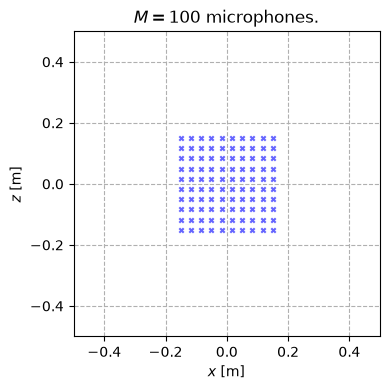

In [4]:
problem.set_mic_array(x_len = 0.3, z_len = 0.3, n_x = 10, n_z = 10)
print("Shape of the measured coord: {}".format(problem.coord.shape))
plot_in_space(problem.coord)

## 2.1. Single plane wave

The method `compute_pres` can be used to evaluate Eq. (1). All you need to do is provide the method with the angles (in degrees) of the plane waves that produced the actual measurement and their corresponding amplitudes. 

**NOTE:** The angles of the plane waves are measured relative to the $z$ axis, so that the $0^{\circ}$ lies at the top of the microphone array (and the $180^{\circ}$ lies at the bottom).

Let's see what the real part of the measured sound field ($\mathcal{R}e\{\mathbf{p}\}$) looks like when a single plane wave is the source.

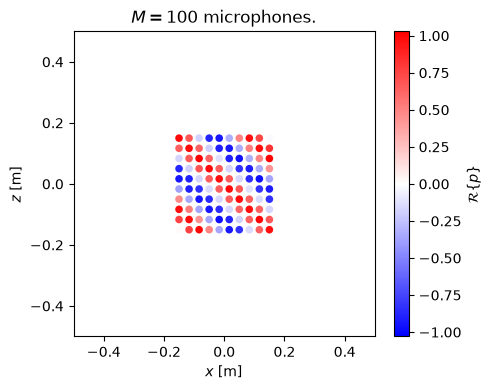

In [5]:
theta_deg = [45]
amps = [1]
# True source term
theta_deg_true = np.arange(0, 360, 1)
x_true = np.zeros(len(theta_deg_true))
x_true[theta_deg_true==theta_deg[0]] = amps[0]

problem.compute_pres(theta_deg = theta_deg, amps = amps)
problem.add_noise(snr = 30)
plot_in_space(problem.coord, problem.b_noisy)

## 2.2. A sum of two plane waves

Summing two plane waves is easy with `compute_pres`. All you need to do is provide a tuple or list of angles (in degrees) and their corresponding amplitudes (each of size 2). 

Let's see what the real part of the measured sound field ($\mathcal{R}e\{\mathbf{p}\}$) looks like when it is the sum of 2 plane waves. You shall notice that the sound field starts to look more complicated. It is already very difficult to determine where the waves are coming from and their relative amplitudes.

**Note:** summing more plane waves is a matter of adding angles and amplitudes to the original tuples or lists.

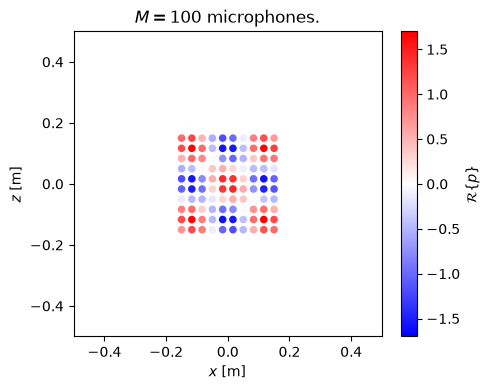

In [6]:
theta_deg = (45, 315)
amps = (1, 0.7)
# True source term
theta_deg_true = np.arange(0, 360, 1)
x_true = np.zeros(len(theta_deg_true))
x_true[theta_deg_true==theta_deg[0]] = amps[0]
x_true[theta_deg_true==theta_deg[1]] = amps[1]

# Forward problem
problem.compute_pres(theta_deg = theta_deg, amps = amps)
problem.add_noise(snr = 30)
plot_in_space(problem.coord, problem.b_noisy)

## 2.3. A smooth distribution of plane waves

The `smooth_sf` method provides a way to compute a smooth distribution of 360 plane waves with amplitudes given by

\begin{equation}
\tilde{a}_i = \sin^2(q \theta_i)/360,
\end{equation}

where $q$ is the amplitude modulation factor and $\theta_i = 2\pi i/N$, with $i=0,\ldots,N-1$.

Let's see what the real part of the measured sound field ($\mathcal{R}e\{\mathbf{p}\}$) looks like when a distribution of many plane waves causes it. You shall notice that the sound field is very complicated, and it is very difficult to determine where the waves are coming from and their relative amplitudes.

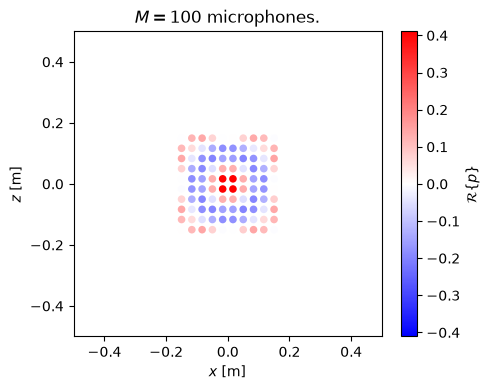

In [7]:
# True source term
factor = 4
theta_deg_true = np.arange(0, 360, 1)
x_true = (1/len(theta_deg_true))*np.sin(factor * np.deg2rad(theta_deg_true))**2
x_true /= np.amax(np.abs(x_true))

problem.smooth_sf(q = factor)
problem.add_noise(snr = snr)
plot_in_space(problem.coord, problem.b_noisy)

# 3. Inverse problem

Now we can set up the inverse problem, estimate plane wave amplitudes, and reconstruct the sound field. We will start by analyzing the sound field caused by the smooth distribution of plane waves. 

## 3.1. Inverse problem setup

The first step in setting up the inverse problem is to determine the number of candidate plane waves to estimate ($L$). Then we can determine the coordinates of each point on the unit circle. We can do this by doing:

\begin{equation}
\theta_{i} = \frac{2 \pi i}{L},
\tag{3}
\end{equation}
where $i = 0, 1, \ldots, L-1$, and $L$ is the desired number of candidate plane waves.

In the wave number domain, $\mathbf{k}$, each coordinate of a candidate plane wave will be:

\begin{equation}
\mathbf{k}_{i} = [k_0 \sin(\theta_{i}), k_0 \cos(\theta_{i})],
\tag{4}
\end{equation}
and given a total of $L$ candidate plane waves, we can form a matrix of candidate wave numbers of shape $L \times 2$.

Each entry of the sensing matrix will be

\begin{equation}
a_{mi} = \exp(\text{-j} \mathbf{k}_i \cdot \mathbf{r}_{\text{m}}),
\tag{5}
\end{equation}
and the resulting inverse problem will be

\begin{equation}
\underbrace{\begin{bmatrix}
\tilde{p}(\mathbf{r}_{0}) \\ \tilde{p}(\mathbf{r}_{1}) \\ \vdots \\ \tilde{p}(\mathbf{r}_{M-1})
\end{bmatrix}}_{\text{measurement}} = 
\underbrace{\begin{bmatrix}
\exp(\text{-j} \mathbf{k}_0 \cdot \mathbf{r}_{0}) & \exp(\text{-j} \mathbf{k}_1 \cdot \mathbf{r}_{0}) & \cdots & \exp(\text{-j} \mathbf{k}_{L-1} \cdot \mathbf{r}_{0}) \\
\exp(\text{-j} \mathbf{k}_0 \cdot \mathbf{r}_{1}) & \exp(\text{-j} \mathbf{k}_1 \cdot \mathbf{r}_{1}) & \cdots & \exp(\text{-j} \mathbf{k}_{L-1} \cdot \mathbf{r}_{1})\\
\vdots & \vdots & \ddots & \vdots\\
\exp(\text{-j} \mathbf{k}_0 \cdot \mathbf{r}_{M-1}) & \exp(\text{-j} \mathbf{k}_1 \cdot \mathbf{r}_{M-1}) & \cdots & \exp(\text{-j} \mathbf{k}_{L-1} \cdot \mathbf{r}_{M-1})\\
\end{bmatrix}}_{\text{sensing matrix} \ \in \ \mathbb{C}^{M \times L}}
\underbrace{\begin{bmatrix}
\tilde{x}_0 \\ \tilde{x}_1 \\ \vdots \\ \tilde{x}_{L-1}
\end{bmatrix}}_{\text{unknowns}}
\tag{6}
\end{equation}

The method `get_sens_mtx` allows you to compute such a sensing matrix with a desired number of candidate plane waves $L$. Note that such a sensing matrix is not tied to the forward problem estimation.

Let's first recompute the forward problem using the `smooth_sf` method, whose sound field is caused by a continuous distribution of sound sources. We will also compute the source term distribution.

In [8]:
problem = SoundField2D(c0 = 340, freq = 2000)
problem.set_mic_array(x_len = 0.3, z_len = 0.3, n_x = 10, n_z = 10)
factor = 4
problem.smooth_sf(q = factor)
problem.add_noise(snr = snr)
theta_deg_true = np.arange(0, 360, 1)
x_true = (1/len(theta_deg_true))*np.sin(factor * np.deg2rad(theta_deg_true))**2

#### We can then form the sensing matrix, perform the SVD and look at the Picard plot.

In [9]:
problem.get_sens_mtx(nwaves = 180)
theta_dir = problem.wave_directions()
u, s, v = regsolvers.csvd(problem.A)

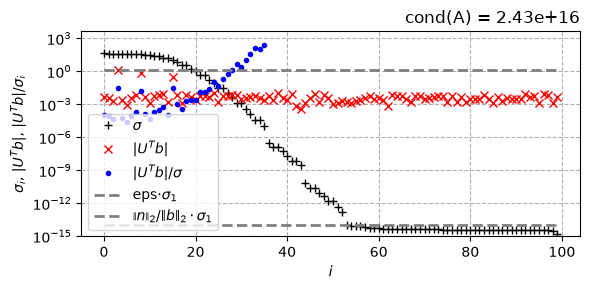

In [10]:
noise_norm = 10**(-snr / 20) * np.linalg.norm(np.abs(problem.b_true))
pyregtools.utils.plot_picard(u, s, problem.b_noisy, noise_norm = noise_norm, figsize = (6,3))

## 3.2. Tikhonov solution and choosing the optimal $\lambda$

Let's try using a regularized solution based on the SVD of $\mathbb{A}$. Again, the reader is referred back to the [Gravity Survey notebook](gravity_survey.ipynb), in which we studied the technique in detail. The SVD was already computed using `csvd`. Now, we can combine it with the measured data to choose an optimal regularization parameter $\lambda$. We will use the L-curve technique in this case. With the optimal $\lambda$, we can also compute the Tikhonov solution via the SVD of $\mathbf{A}$ and the noisy data.

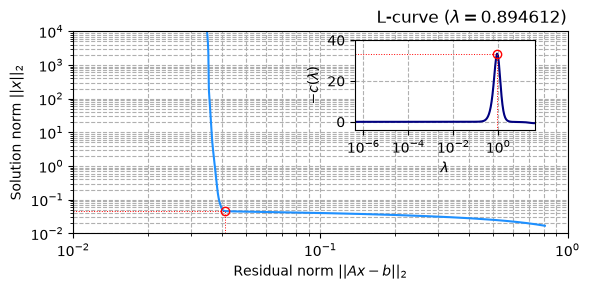

In [11]:
lam_l = regchoice.l_curve(u, s, problem.b_noisy, r_min = 1e-8, plotit = True) # evoke reg choice method
x_tik = regsolvers.tikhonov(u, s, v, problem.b_noisy, lam_l) # evoke tikhonov solver passing the optimal reg parameter

### Plotting the normalized energy distribution

We can use `plot_solution_field` to plot a normalized version of the magnitude of the plane waves. This is useful for determining the directions from which the main part of the energy in such a sound field comes. 

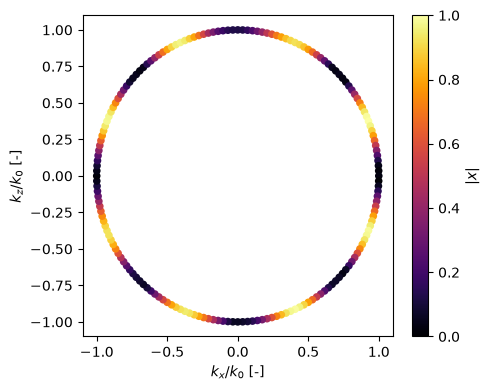

In [12]:
problem.plot_solution_field(x_tik)

# 4. Comparing different solvers

After finding the optimal value of $\lambda$, we can compare the **relative amplitudes** of the solution given by a few solvers. `PyRegTools` provides several solvers in the `regsolvers` module. We will compare:

- Least squares solver;
- Tikhonov solver via SVD (already computed);
- Ridge solver from scikit-learn;

## 4.1. Least squares solver

This solver computes the solution using numpy least-squares using <a href="https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html" target="_blank">`numpy.linalg.lstsq`</a>. It is equivalent to using the Tikhonov solution with $\lambda = 0$. You will note that the error of such a solution is quite high, since least-squares is prone to overfitting.

In [13]:
x_ls = regsolvers.least_sq(problem.A, problem.b_noisy)

## 4.2. Ridge regression via scikit-learn

This solver computes the solution using scikit-learn Ridge regression (another name for the Tikhonov solution) using <a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html" target="_blank">`sklearn.linear_model.Ridge`</a> (**addapted for complex matrices and data**). Note that in scikit-learn Ridge regression notation, the regularization parameter is equivalent to $\lambda^2$.

In [14]:
x_ridge = regsolvers.sklearn_ridge_c(problem.A, problem.b_noisy, lam_l**2) 

## 4.3. Ridge regression from cvxpy

This solver computes the solution using Ridge regression (another name for the Tikhonov solution) using <a href="https://www.cvxpy.org/" target="_blank">`cvxpy`</a>. Note that this solver can be used with real or complex matrices or data. It also provides a way to run a Lasso regression instead of a Ridge regression. We will explore Lasso regression in this notebook.

In [15]:
x_cvx = regsolvers.cvx_reg(problem.A, problem.b_noisy, lam_l, is_lasso = False, is_complex = True)

### Comparing solvers so far

As expected, the least-squares solution is prone to noise and overfitting. Furthermore, the solutions of the other solvers are similar in this case. The CVX solver performed slightly worse, but this can be case-specific.

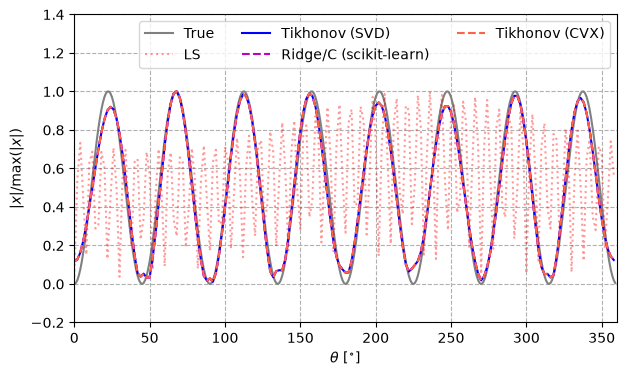

In [16]:
plt.figure(figsize = (7,4))
plt.plot(theta_deg_true, np.abs(x_true)/np.amax(np.abs(x_true)), color ='grey', label = "True")
plt.plot(np.rad2deg(theta_dir), np.abs(x_ls)/np.amax(np.abs(x_ls)), 
        ':', color = 'red', alpha = 0.4, label = "LS")
plt.plot(np.rad2deg(theta_dir), np.abs(x_tik)/np.amax(np.abs(x_tik)), 
        '-b',label = "Tikhonov (SVD)")
plt.plot(np.rad2deg(theta_dir), np.abs(x_ridge)/np.amax(np.abs(x_ridge)),
        '--m',label = "Ridge/C (scikit-learn)")
plt.plot(np.rad2deg(theta_dir), np.abs(x_cvx)/np.amax(np.abs(x_cvx)),
        '--', color = 'tomato' ,label = 'Tikhonov (CVX)')
plt.legend(ncols = 3)
plt.grid(linestyle = '--')
plt.xlim((0,360))
plt.ylim((-0.2,1.4))
plt.xlabel(r"$\theta$ [$^{\circ}$]")
plt.ylabel(r"$|x|/\text{max}(|x|)$");

## 4.4. Conjugate Gradient Least Squares solver

In the [Image deblurring notebook](image_deblurring.ipynb), we studied some iterative solvers, including the Conjugate Gradient Least Squares solver (CGLS - `iterativesolvers.cgls`). Please refer to the mentioned notebook for more theory. 

CGLS exhibits **semiconvergence** when applied to ill-posed problems. The first iterations recover the most relevant components of the solution, while later iterations may amplify 
the measurement noise. Therefore, **the number of iterations acts as a regularization parameter**. Stopping the algorithm at an appropriate iteration can produce a better reconstruction than allowing it to converge fully. We can use the `lcurve_discrete` function for choosing the optimal iteration. We can now apply CGLS to the problem at hand and compare it to the Tikhonov solution via SVD.

In [17]:
num_iterations = 50
x_est_h, sol_norms, res_norms = iterativesolvers.cgls(problem.A, problem.b_noisy, max_it=num_iterations)
print("Shape of Solution history: {}".format(x_est_h.shape))

Shape of Solution history: (180, 50)


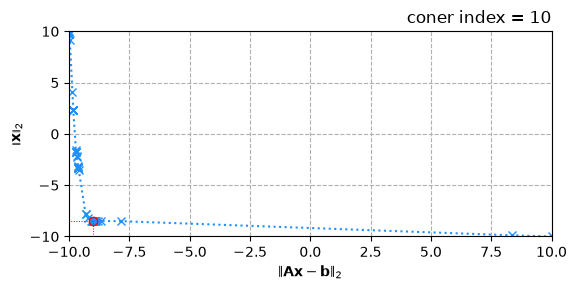

In [18]:
k_l = regchoice.lcurve_discrete(res_norms, sol_norms, plotit=True)
x_cgls = x_est_h[:,k_l]

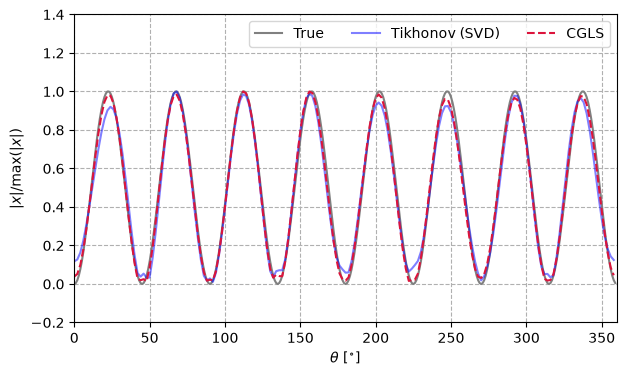

In [19]:
plt.figure(figsize = (7,4))
plt.plot(theta_deg_true, np.abs(x_true)/np.amax(np.abs(x_true)), color ='grey', label = "True")
plt.plot(np.rad2deg(theta_dir), np.abs(x_tik)/np.amax(np.abs(x_tik)), 
        '-b',label = "Tikhonov (SVD)", alpha = 0.5)
plt.plot(np.rad2deg(theta_dir), np.abs(x_cgls)/np.amax(np.abs(x_cgls)),
        '--', color = 'crimson',label = "CGLS")
plt.legend(ncols = 3)
plt.grid(linestyle = '--')
plt.xlim((0,360))
plt.ylim((-0.2,1.4))
plt.xlabel(r"$\theta$ [$^{\circ}$]")
plt.ylabel(r"$|x|/\text{max}(|x|)$");

# 5. Reconstruction

Once we have obtained a good approximation of the plane wave amplitudes, we can use it to predict the sound field at locations where no measurements were taken. In other words, we wish to **reconstruct** the quantity of interest at unobserved locations. Those locations may include points within the array's aperture (interpolation) or out of it (extrapolation).

Importantly, reconstruction is a **forward problem**. Since we have already estimated the source distribution $\hat{\mathbf{x}}$ by solving the regularized inverse problem, we simply compute

\begin{equation}
\mathbf{b}_{\mathrm{r}} =
\mathbf{A}_{\mathrm{r}}\hat{\mathbf{x}},
\tag{7}
\end{equation}

where $\mathbf{A}_{\mathrm{r}}$ is the forward operator evaluated at the desired reconstruction locations.

Let's do something simple: we can use the original `problem` object, and then:

- create the reconstruction array of coordinates;
- compute the reconstruction matrix;
- compute the reconstruction with Eq. (7)

We will use the Tikhonov solution already computed. We will also calculate a reference sound field at the reconstruction coordinates and then compare the reconstruction and reference sound pressure fields.

In [20]:
coord_recon = problem.pt_array(x_len = 1.0, z_len = 1.0, n_x = 100, n_z = 100)
print("Shape of the reconstruction coord: {}".format(coord_recon.shape))

Shape of the reconstruction coord: (10000, 2)


In [21]:
k_rec_vec = problem.k0 * np.array([np.sin(theta_dir), np.cos(theta_dir)])
Arec = np.exp(-1j * coord_recon @ k_rec_vec)
print("Shape of the reconstruction matrix: {}".format(Arec.shape))

Shape of the reconstruction matrix: (10000, 180)


In [22]:
pres_recon = Arec @ x_tik
print("Shape of the reconstructed pressure: {}".format(pres_recon.shape))

Shape of the reconstructed pressure: (10000,)


### Reference sound field

In [23]:
ref = SoundField2D(c0 = problem.c0, freq = problem.freq) # instantiate
ref.set_mic_array(x_len = coord_recon[:,0].max()-coord_recon[:,0].min(), 
                  z_len = coord_recon[:,1].max()-coord_recon[:,1].min(), 
                  n_x = 100, n_z = 100)
ref.smooth_sf(q = factor)

### Comparison

Note that in this case, where the plane-wave distribution is smooth, the reconstruction is quite precise, even at locations far from the array aperture. 

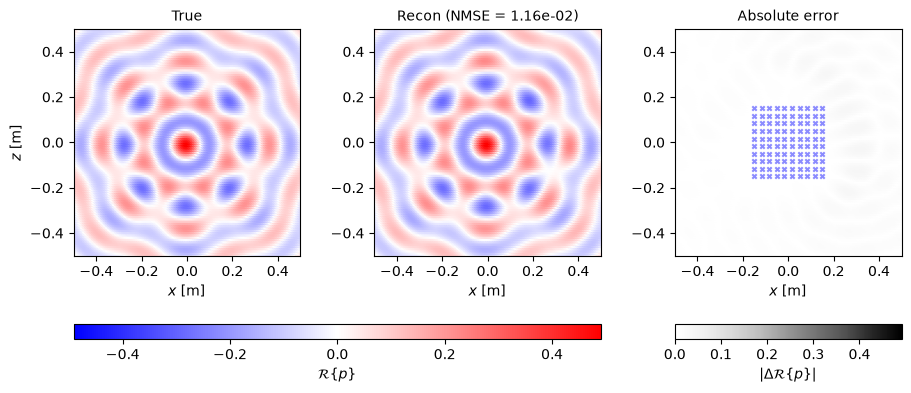

In [24]:
compare_sf(figsize = (9,4), coord = coord_recon, pres_ref = ref.b_true, pres_recon = pres_recon)

### Plane-wave amplitudes and spatial energy

The plane-wave expansion resembles a Fourier representation, but its sensing matrix is generally not unitary. The candidate plane waves are not necessarily **orthogonal** over the finite measurement aperture. Furthermore, the candidate wave vectors lie on a circle of radius $k_0$, rather than on a conventional Cartesian DFT grid, and the number of candidate plane waves can exceed the number of measurements.

Consequently, **Parseval's theorem** does not directly relate the squared norm of the plane-wave coefficients to the mean squared sound pressure in space. That is why the normalized solutions were plotted earlier.

Furthermore, the numerical values of the plane-wave coefficients depend on the angular discretization. For a smooth angular distribution, increasing the number of candidate plane waves generally decreases the magnitude of each discrete coefficient.

Therefore, the squared norm of the estimated plane-wave amplitudes should not be interpreted directly as the spatial sound-pressure energy. This does not invalidate the sound field reconstruction, which is usually recovered at the same scale as the measurements, as shown below.

In [25]:
# Spatial mean squared pressure
E_space = np.mean(np.abs(ref.b_true)**2)

# Pressure reconstructed at the measurement positions
b_tik = Arec @ x_tik
E_recon = np.mean(np.abs(b_tik)**2)

# Squared norm of the estimated plane-wave coefficients
E_coeff = np.linalg.norm(x_tik)**2

print(f"Reference spatial mean square: {E_space:.4e}")
print(f"Reconstructed spatial mean square: {E_recon:.4e}")
print(f"Percentual error in energy: {100*(E_recon-E_space)/E_space:.2f} %")
print(f"Coefficient squared norm: {E_coeff:.4e}")

Reference spatial mean square: 1.0915e-02
Reconstructed spatial mean square: 1.1058e-02
Percentual error in energy: 1.31 %
Coefficient squared norm: 2.1125e-03


# 6. Sparse sound field analysis and reconstruction

Now, we can use `SoundField2D` to create a measurement caused by a sparse distribution of plane waves. We will create a sound field caused by the sum of 2 plane waves.

This means that while the measured sound field is smooth, its representation in the solution basis vectors is sparse. In this case, only 2 components are different than 0. We say that the solution is $K$ sparse, with $K = 2$ in this case.

Additionally, we will reduce the number of measurements by creating a random microphone array with $M=40$ microphones.

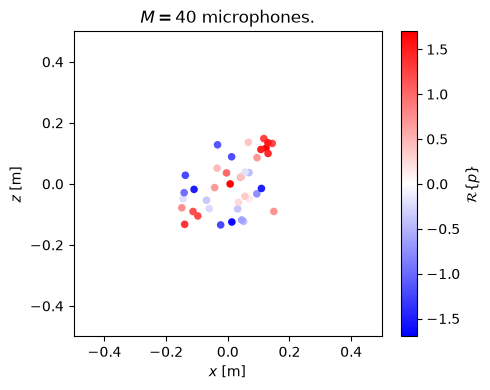

In [26]:
theta_deg = (45, 315)
amps = (1, 0.7)

# Forward problem
problem = SoundField2D(c0 = 340, freq = 2000)
problem.set_mic_random_array(x_len = 0.3, z_len = 0.3, m = 40)
problem.compute_pres(theta_deg = theta_deg, amps = amps)
problem.add_noise(snr = 30)
noise_norm = 10**(-snr / 20) * np.linalg.norm(np.abs(problem.b_true))
plot_in_space(problem.coord, problem.b_noisy)

# True source term
theta_deg_true = np.arange(0, 360, 1)
x_true = np.zeros(len(theta_deg_true))
x_true[theta_deg_true==theta_deg[0]] = amps[0]
x_true[theta_deg_true==theta_deg[1]] = amps[1]

## 6.1. Tikhonov solution

Now, we can compute the Tikhonov solution for this case. Note that such a regularization technique promotes a solution that tends to be smooth due to the penalty imposed by the $\ell_2$ norm.

You will notice that while the true solution is sparse (there are only values different than zero at $45^{\circ}$ and $315^{\circ}$), the solution is smooth, with maximum values appearing near such angles. The reader can experiment with the number of points in the array, the array aperture, etc., and observe the effects on the solution,  reconstruction, and matrix coherence.

In [27]:
problem.get_sens_mtx(nwaves = 180)
theta_dir = problem.wave_directions()
u, s, v = regsolvers.csvd(problem.A)

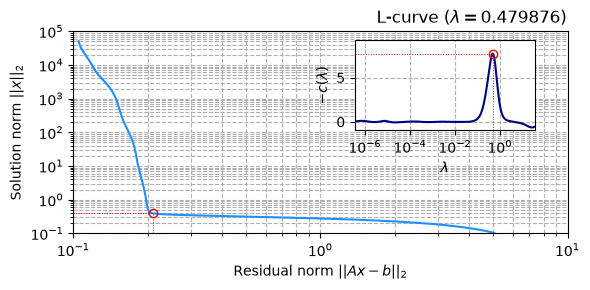

In [28]:
lam_l = regchoice.l_curve(u, s, problem.b_noisy, r_min = 1e-8, plotit = True) # evoke reg choice method
x_tik = regsolvers.tikhonov(u, s, v, problem.b_noisy, lam_l) # evoke tikhonov solver passing the optimal reg parameter

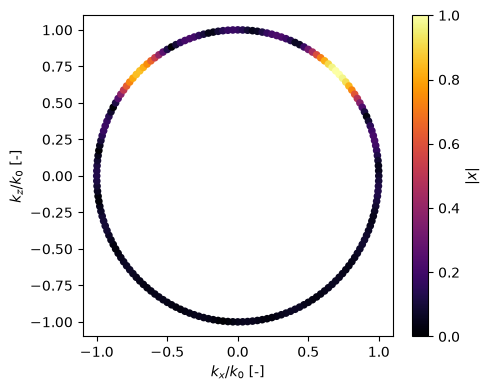

In [29]:
problem.plot_solution_field(x_tik)

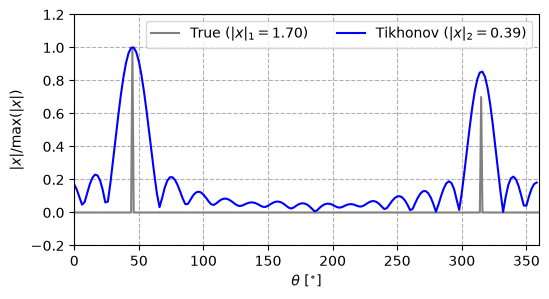

In [30]:
plt.figure(figsize = (6,3))
plt.plot(theta_deg_true, np.abs(x_true)/np.amax(np.abs(x_true)), color ='grey', label = r"True ($|x|_1 = ${:.2f})".format(np.linalg.norm(x_true, 1)))
plt.plot(np.rad2deg(theta_dir), np.abs(x_tik)/np.amax(np.abs(x_tik)), 
        '-b',label = r"Tikhonov ($|x|_2 = ${:.2f})".format(np.linalg.norm(x_tik, 2)), alpha = 1)
plt.legend(ncols = 3)
plt.grid(linestyle = '--')
plt.xlim((0,360))
plt.ylim((-0.2,1.2))
plt.xlabel(r"$\theta$ [$^{\circ}$]")
plt.ylabel(r"$|x|/\text{max}(|x|)$");

## Reconstruction vs. reference

With such a sparse distribution of plane waves and a relatively small number of sensors, the reconstruction is accurate only near the measured coordinates. The smoothness-promoting nature of standard Tikhonov regularization is ill-suited to a sparse angular spectrum, as we can see from the plotted normalized solutions.

In [31]:
coord_recon = problem.pt_array(x_len = 1.0, z_len = 1.0, n_x = 100, n_z = 100)
k_rec_vec = problem.k0 * np.array([np.sin(theta_dir), np.cos(theta_dir)])
Arec = np.exp(-1j * coord_recon @ k_rec_vec)
pres_recon = Arec @ x_tik

In [32]:
ref = SoundField2D(c0 = problem.c0, freq = problem.freq) # instantiate
ref.set_mic_array(x_len = coord_recon[:,0].max()-coord_recon[:,0].min(), 
                  z_len = coord_recon[:,1].max()-coord_recon[:,1].min(), 
                  n_x = 100, n_z = 100)
ref.compute_pres(theta_deg = theta_deg, amps = amps)

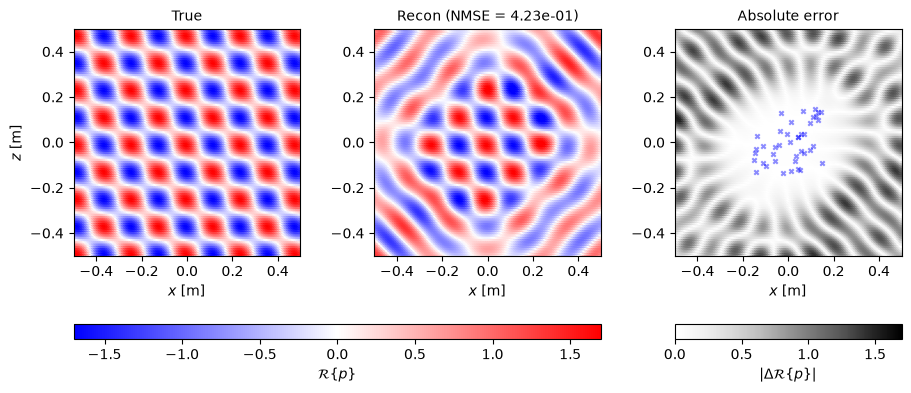

In [33]:
compare_sf(figsize = (9,4), coord = coord_recon, pres_ref = ref.b_true, pres_recon = pres_recon)

# 7. Sparse Regularization and Compressed Sensing

In the previous examples, we used Tikhonov regularization (and CGLS) to estimate the plane-wave amplitudes. Although this approach can accurately reconstruct the sound field, it does not necessarily recover a sparse angular spectrum.

Consider the sound field consisting of only two plane waves. Ideally, its angular spectrum should contain only two **nonzero** coefficients. This suggests that we should incorporate **sparsity** into the inverse problem.

### The $\ell_0$ Pseudonorm

A natural measure of sparsity is the $\ell_0$ pseudonorm, which counts the number of nonzero coefficients and is given by

\begin{equation}
\|\mathbf{x}\|_0 = \#\{i:x_i\neq 0\},
\tag{8}
\end{equation}



We could therefore solve

\begin{equation}
\begin{gathered}
\text{min}(\left\|\textbf{x}\right\|_{0}), \ \ \, \text{subjected to} \ \ \ \left\|\textbf{Ax -  b}\right\|^{2}_{2} \leq k \ \left\|\textbf{n}\right\|^{2}_{2}  \\ \text{or} \\
\hat{\mathbf{x}} = \operatorname*{arg\,min}_{\mathbf{x}}\left\{\|\mathbf{A}\mathbf{x}-\mathbf{b}\|_2^2 + \lambda\|\mathbf{x}\|_0\right\}.
\end{gathered}
\tag{9}
\end{equation}

The **residual norm** measures agreement with the observations, while the $\ell_0$ **solution norm** penalizes the number of active plane waves (the more active coefficients, the higher the penalty).

Unfortunately, minimizing the $\ell_0$ pseudonorm is a **nonconvex**, **combinatorial** optimization problem that is generally difficult to solve for large systems.

### The $\ell_1$ Relaxation

A practical alternative is to replace the $\ell_0$ pseudonorm with the convex $\ell_1$ norm,

\begin{equation}
\|\mathbf{x}\|_1 = \sum_{i=1}^{L}|x_i|.
\tag{10}
\end{equation}

This leads to the following formulations:

\begin{equation}
\text{min}(\left\|\textbf{x}\right\|_{1}), \ \ \, \text{subjected to} \ \ \ \left\|\textbf{Ax -  b}\right\|^{2}_{2} \leq k \ \left\|\textbf{n}\right\|^{2}_{2} 
\tag{11}
\end{equation}

or to the **Lasso** problem, given by

\begin{equation}
\hat{\mathbf{x}}_\lambda = \operatorname*{arg\,min}_{\mathbf{x}}\left\{\|\mathbf{A}\mathbf{x}-\mathbf{b}\|_2^2+\lambda\|\mathbf{x}\|_1\right\}.
\tag{12}
\end{equation}

Unlike the squared $\ell_2$ penalty used in standard Tikhonov regularization, the $\ell_1$ penalty encourages some coefficients to become exactly zero. The resulting solution can therefore identify a small number of dominant plane-wave directions while fitting the measured sound field. This is a central idea in **compressed sensing**, where sparse signals may be recovered from a limited number of measurements under suitable conditions on the sensing matrix.


## 7.1. Why does the $\ell_1$ norm promote sparsity?

Consider two plane waves whose contributions to the measured pressure are nearly indistinguishable. In this situation, the same sound field may be approximated by concentrating the amplitude in a single direction or distributing it across several nearby directions.

The squared $\ell_2$ penalty favors distributing the amplitude, because splitting a coefficient into smaller contributions reduces the sum of their squares. The $\ell_1$ penalty, on the other hand, does not offer this advantage. More importantly, the $\ell_1$ penalty can force small coefficients to become exactly zero.

To understand this, consider a simple scalar inverse problem with a real-valued unknown:

$$
\hat{x}=\operatorname*{arg\,min}_x
\left\{\frac12(x-b)^2+\lambda|x|\right\}.
$$

Its solution is the **soft-thresholding operator**:

$$
\hat{x}=
\begin{cases}
b-\lambda, & b>\lambda,\\
0, & |b|\leq\lambda,\\
b+\lambda, & b<-\lambda.
\end{cases}
$$

Thus, coefficients below a threshold are set to zero, while larger coefficients are scaled down.

This explains the sparsity-promoting behavior of $\ell_1$ regularization: the solution can retain a few dominant components while suppressing weaker contributions.

For a general sensing matrix, the coefficients interact through the forward model, so the solution cannot be obtained by simply thresholding each coefficient independently. Nevertheless, the same underlying mechanism favors sparse solutions.

We can now try sparse solutions with Eqs. (11) and (12). The solvers are implemented in the `regsolvers` module of `PyRegTools`. Let's see how they behave.

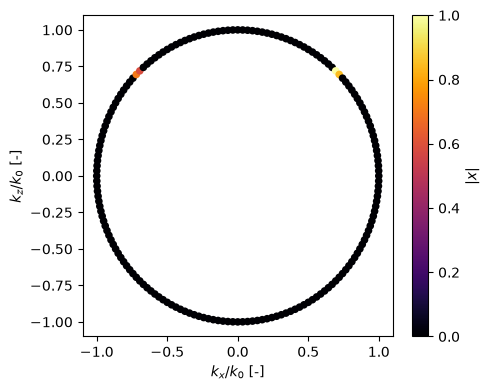

In [34]:
x_cs = regsolvers.cvx_constrained(problem.A, problem.b_noisy, noise_norm, is_cs = True, is_complex = True)
problem.plot_solution_field(x_cs)

In [35]:
x_cs_norm = x_cs/np.amax(np.abs(x_cs))
ind_tol = np.where(x_cs_norm >= 1e-4)
print("Shape of full solution: {}".format(x_cs.shape))
print("Shape of coefficients above -40 dB: {}".format(ind_tol[0].shape))

Shape of full solution: (180,)
Shape of coefficients above -40 dB: (7,)


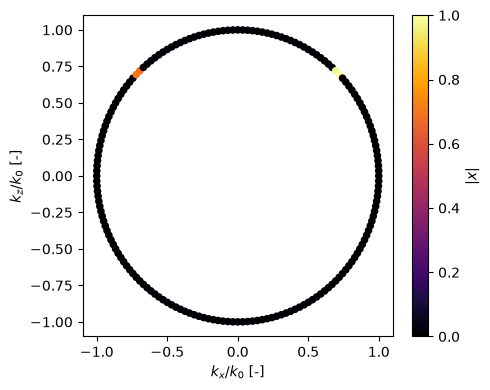

In [36]:
x_lasso = regsolvers.cvx_reg(problem.A, problem.b_noisy, 0.25, is_lasso = True, is_complex = True)
problem.plot_solution_field(x_lasso)

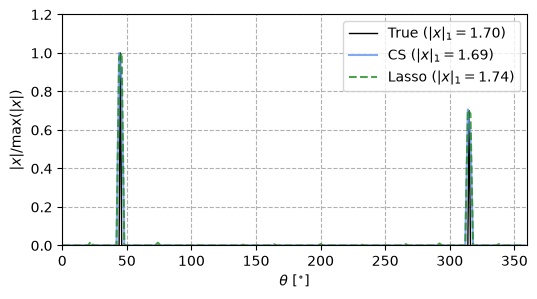

In [37]:
plt.figure(figsize = (6,3))
plt.plot(theta_deg_true, np.abs(x_true)/np.amax(np.abs(x_true)), color ='k', 
         label = r"True ($|x|_1 = ${:.2f})".format(np.linalg.norm(x_true, 1)), linewidth = 1.0)
plt.plot(np.rad2deg(theta_dir), np.abs(x_cs)/np.amax(np.abs(x_cs)), 
        '-', color = 'cornflowerblue', label = r"CS ($|x|_1 = ${:.2f})".format(np.linalg.norm(x_cs, 1)), alpha = 0.8)
plt.plot(np.rad2deg(theta_dir), np.abs(x_lasso)/np.amax(np.abs(x_lasso)), 
        '--', color = 'forestgreen',label = r"Lasso ($|x|_1 = ${:.2f})".format(np.linalg.norm(x_lasso, 1)), alpha = 0.8)
plt.legend(ncols = 1)
plt.grid(linestyle = '--')
plt.xlim((0,360))
plt.ylim((0,1.2))
plt.xlabel(r"$\theta$ [$^{\circ}$]")
plt.ylabel(r"$|x|/\text{max}(|x|)$");

## Reconstruction vs. reference

Let's try reconstructing the sound field with the **sparse** solution (either `x_cs` or `x_lasso`. You will notice that the reconstruction is very precise, even beyond the array's aperture, given the reduced number of sensors (go back a few cells to check how the Tikhonov reconstruction was).

I know it's a bit like cheating in this case, since we know the sound field is $ K=2$-sparse. In reality, we will never know a priori how sparse the sound field is. Anyhow, the demonstration serves its purpose as an introductory example.

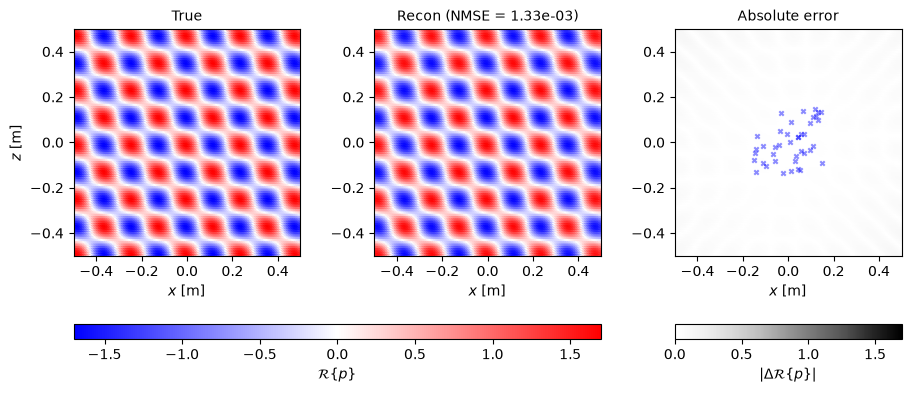

In [38]:
pres_recon = Arec @ x_cs
compare_sf(figsize = (9,4), coord = coord_recon, pres_ref = ref.b_true, pres_recon = pres_recon)    

## 7.2. Conditions for Sparse Recovery

In the previous example, we used $\ell_1$ regularization to reconstruct a sound field generated by a small number of plane waves. The estimated angular spectrum was sparse, containing only a few significant coefficients.

However, **sparse recovery is not always guaranteed**. Its success depends on the number of active plane waves ($K$), the number of measurements ($M$), and the properties of the sensing matrix.

Let us consider the linear inverse problem $\mathbf{Ax} = \mathbf{b}$. We assume that the true coefficient vector is $K$-sparse, meaning that:

\begin{equation}
\|\mathbf{x}\|_0 = K,
\end{equation}

where $K$ is the number of nonzero coefficients.

### 7.2.1. Mutual Coherence

An important requirement for sparse recovery is that different columns of the sensing matrix should be sufficiently distinguishable.

The **mutual coherence** of $\mathbf{A}$ is defined as

\begin{equation}
\mu(\mathbf{A}) =
\max_{i\neq j}
\frac{|\mathbf{a}_i^H\mathbf{a}_j|}
{\|\mathbf{a}_i\|_2\|\mathbf{a}_j\|_2},
\tag{13}
\end{equation}


where $\mathbf{a}_i$ denotes the $i$-th column of $\mathbf{A}$.

Mutual coherence measures the largest normalized correlation between two distinct columns. Its values lie between zero and one:

- $\mu(\mathbf{A})=0$ indicates mutually orthogonal columns.
- $\mu(\mathbf{A})=1$ indicates that at least two columns are linearly dependent.

In our sound-field problem, each column represents the pressure field produced by a plane wave, sampled at the microphone positions. Thus, if two columns are highly correlated, their corresponding propagation directions are difficult to distinguish from the measurements.

Note also that the sensing matrix coherence will depend on several factors in this case (see Eq. (6)):

- the array coordinates, which are impacted by the number of sensors and the array's aperture;
- the number of plane waves (a lot of them decrease coherence) because each wave becomes more and more similar to its neighbors;

#### Mutual Coherence and Sparsity

For the noiseless inverse problem, a classical sufficient condition for exact recovery of a $K$-sparse solution by $\ell_1$ minimization is

\begin{equation}
\mu(\mathbf{A}) < \frac{1}{2K-1}.
\tag{14}
\end{equation}

This result assumes that the columns are normalized and that recovery is performed using the equality-constrained formulation:

\begin{equation}
\min_{\mathbf{x}}\|\mathbf{x}\|_1
\quad \text{subject to} \quad
\mathbf{A}\mathbf{x}=\mathbf{b}.
\end{equation}

For example, if the sound field contains only two plane waves ($K=2$), the sufficient condition becomes

\begin{equation}
\mu(\mathbf{A}) < \frac{1}{3}.
\end{equation}

Therefore, recovering more plane waves requires a sensing matrix with lower mutual coherence. Importantly, this is a **sufficient but not necessary condition**. Sparse recovery may still succeed when the inequality is not satisfied.

In `PyRegTools`, mutual coherence can be calculated using the method `gram_matrix` from the `regsolvers` module. Let's do a small experiment varying the number of plane waves in our model.

In [39]:
n_waves = np.arange(20, 370, 10)
coherence = np.zeros(len(n_waves))
nmse = np.zeros(len(n_waves))
for jn, nw in enumerate(n_waves):
    # Matrix coherence
    problem.get_sens_mtx(nwaves = nw)
    gram_mtx, coherence[jn] = regsolvers.gram_matrix(problem.A)
    # solution and reconstruction
    x_cs = regsolvers.cvx_constrained(problem.A, problem.b_noisy, noise_norm, is_cs = True, is_complex = True)
    theta_dir = problem.wave_directions()
    k_rec_vec = problem.k0 * np.array([np.sin(theta_dir), np.cos(theta_dir)])
    Arec = np.exp(-1j * coord_recon @ k_rec_vec)
    pres_recon = Arec @ x_cs
    nmse[jn] = pyregtools.utils.nmse_fun(x_ref=ref.b_true, x_meas=pres_recon)

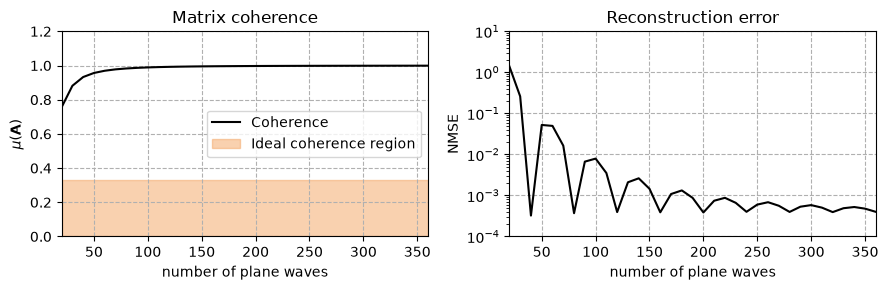

In [40]:
fig, axs = plt.subplots(1, 2, figsize = (9,3))
axs[0].plot(n_waves, coherence, 'k', label = 'Coherence')
axs[0].fill_between(n_waves, np.zeros(len(n_waves)), (1/3)*np.ones(len(n_waves)), 
                    alpha = 0.5, color = 'sandybrown', label = 'Ideal coherence region')
axs[0].legend(loc = 'center right')
axs[0].grid(linestyle = '--')
axs[0].set_xlim((n_waves[0], n_waves[-1]))
axs[0].set_ylim((0,1.2))
axs[0].set_xlabel(r'number of plane waves')
axs[0].set_ylabel(r'$\mu(\mathbf{A})$')
axs[0].set_title(r'Matrix coherence')
axs[1].semilogy(n_waves, nmse, color = 'k')
axs[1].grid(linestyle = '--')
axs[1].set_xlim((n_waves[0], n_waves[-1]))
axs[1].set_ylim((1e-4, 10))
axs[1].set_xlabel(r'number of plane waves')
axs[1].set_ylabel(r'NMSE')
axs[1].set_title(r'Reconstruction error')
plt.tight_layout()

### 7.2.2. How Many Measurements Are Necessary?

Another important question is how many microphones are required to recover a $K$-sparse angular spectrum. Under suitable conditions on the sensing matrix, compressed sensing theory provides a stronger scaling relationship:

\begin{equation}
M \gtrsim C K \log\left(\frac{L}{K}\right),
\tag{15}
\end{equation}


where $C$ depends on the sensing matrix and the desired recovery guarantees. The constant $C$ in the compressed-sensing scaling law is not universal. Its value depends on the sensing matrix model, the recovery algorithm, and the desired recovery probability and accuracy.

Consequently, this relationship should be interpreted as a theoretical scaling law rather than a formula for calculating the exact number of measurements required.

In particular, the classical scaling is established under suitable assumptions on the sensing matrix, which are not necessarily satisfied by the plane-wave sensing matrices considered here.

For our sound-field problem, the number of microphones required for reliable sparse recovery must therefore be investigated together with the microphone geometry, measurement aperture, frequency, and angular discretization.


This indicates that sparse signals can sometimes be reconstructed using substantially fewer measurements than unknown coefficients ($M\ll L$).

However, this scaling is established for suitable classes of sensing matrices and cannot be applied directly to an arbitrary microphone array.


### 7.2.3. Restricted Isometry Property (RIP)

Another important concept in compressed sensing is the **Restricted Isometry Property (RIP)**, which describes how well a sensing matrix preserves the Euclidean norm of sparse vectors.

Consider a sensing matrix $\mathbf{A}\in\mathbb{C}^{M\times L}$ with columns normalized to unit Euclidean norm. The matrix satisfies the RIP of order $K$ with restricted isometry constant $\delta_K$ if

\begin{equation}
(1-\delta_K)\|\mathbf{x}\|_2^2
\leq
\|\mathbf{A}\mathbf{x}\|_2^2
\leq
(1+\delta_K)\|\mathbf{x}\|_2^2.
\tag{16}
\end{equation}

for every vector $\mathbf{x}\in\mathbb{C}^L$ containing at most $K$ nonzero coefficients.

The smallest nonnegative value of $\delta_K$ satisfying these inequalities is called the **restricted isometry constant**.

#### Physical interpretation

In our sound-field reconstruction problem, $\mathbf{x}$ represents the amplitudes of candidate plane waves, while $\mathbf{A}\mathbf{x}$ represents the resulting pressure measurements.

The RIP states that, for any combination of at most $K$ plane waves, the sensing matrix approximately preserves the squared Euclidean norm of the coefficient vector.

If $\delta_K$ is small, different sparse combinations of plane waves are less likely to become indistinguishable after measurement.

Notice that the RIP concerns only **sparse vectors**. It does not require the sensing matrix to preserve the norm of every possible vector, which would generally be impossible when $M<L$.

#### Why is the RIP useful?

The RIP provides theoretical guarantees for the uniqueness and stability of sparse reconstruction.

For example, the difference between two $K$-sparse vectors can contain up to $2K$ nonzero coefficients. Therefore, if

\begin{equation}
\delta_{2K}<1,
\end{equation}

the sensing matrix cannot map two distinct $K$-sparse vectors to the same measurements. This guarantees uniqueness of the sparse representation.

Stronger RIP conditions also guarantee successful recovery using $\ell_1$ minimization. A classical sufficient condition is

\begin{equation}
\delta_{2K}<\sqrt{2}-1.
\end{equation}

Under this condition, basis pursuit can recover a $K$-sparse signal exactly from noiseless measurements. Related results guarantee stable reconstruction in the presence of noise.

These conditions are **sufficient but not necessary**: sparse recovery may succeed even when the RIP bounds are not satisfied.

#### Relationship with mutual coherence

The RIP is closely related to the mutual coherence of the sensing matrix. The restricted isometry constants satisfy:

\begin{equation}
\delta_K\leq(K-1)\mu(\mathbf{A}).
\end{equation}

Thus, low mutual coherence provides an upper bound on the RIP constant.

However, this bound can be conservative. A matrix may have acceptable restricted isometry constants even when the coherence-based estimate is too large to establish a useful guarantee.

#### How difficult is it to evaluate the RIP?

Unlike mutual coherence, which can be calculated directly from the Gram matrix, evaluating the RIP constants is computationally demanding.

For a given order $K$, one must consider every possible subset $S$ of $K$ columns of $\mathbf{A}$ and examine the eigenvalues of

\begin{equation}
\mathbf{A}_S^H\mathbf{A}_S,
\end{equation}

where $\mathbf{A}_S$ contains only the selected columns. The number of possible subsets is

\begin{equation}
\binom{L}{K}=\frac{L!}{K!(L-K)!},
\end{equation}

which grows rapidly with $L$ and $K$.

Consequently, exact RIP calculations are generally impractical for large sensing matrices. In practice, researchers often use theoretical bounds, mutual coherence, or numerical experiments with randomly selected subsets.

#### Implications for sound-field reconstruction

For our plane-wave sensing matrix, nearby candidate directions may generate strongly correlated columns, especially at low frequencies or when the microphone aperture is small. This can produce large restricted isometry constants, making theoretical recovery guarantees difficult to establish.

For this reason, **mutual coherence is a more practical diagnostic**, while RIP provides a broader theoretical explanation of why the geometry of the sensing matrix matters for sparse recovery.

## 7.3. Choosing the Regularization Parameter for LASSO

So far, we have considered two approaches to sparse reconstruction. The first is the constrained formulation, also known as **basis pursuit denoising**:

\begin{equation}
\hat{\mathbf{x}} =
\operatorname*{arg\,min}_{\mathbf{x}}
\|\mathbf{x}\|_1
\quad
\text{subject to}
\quad
\|\mathbf{A}\mathbf{x}-\mathbf{b}\|_2 \leq k \ \left\|\textbf{n}\right\|^{2}_{2},
\end{equation}


In practice, however, the noise level may not be known accurately. Furthermore, the residual may contain modeling errors, such as those caused by discretizing the candidate plane-wave directions. Choosing $k \ \left\|\textbf{n}\right\|^{2}_{2}$ too small can make the optimization problem infeasible. 

An alternative is the **penalized Lasso formulation**:

\begin{equation}
\hat{\mathbf{x}}_\lambda =
\operatorname*{arg\,min}_{\mathbf{x}}
\left\{
\|\mathbf{A}\mathbf{x}-\mathbf{b}\|_2^2
+
\lambda\|\mathbf{x}\|_1
\right\}.
\end{equation}

Here, $\lambda$ controls the compromise between fitting the measurements and promoting sparsity. Small values allow more coefficients to contribute to the reconstruction, while large values favor sparser solutions, potentially at the expense of reconstruction accuracy.

Several strategies can be used to select $\lambda$.

### 7.3.1. Discrepancy Principle

If the noise level is known, we can select $\lambda$ such that the residual norm approximately matches the expected noise norm:

\begin{equation}
\|\mathbf{A}\hat{\mathbf{x}}_\lambda-\mathbf{b}\|_2
\approx \epsilon.
\end{equation}


This prevents the solution from fitting the measurement noise unnecessarily. However, the method requires a reliable estimate of the noise level and should account for possible modeling errors.

### 7.3.2. L-curve

The L-curve represents the tradeoff between the residual norm and the regularization penalty:

\begin{equation}
\left(
\log\|\mathbf{A}\hat{\mathbf{x}}_\lambda-\mathbf{b}\|_2,
\quad
\log\|\hat{\mathbf{x}}_\lambda\|_1
\right).
\end{equation}


A solution near a pronounced corner may provide a reasonable compromise between data fitting and sparsity.

Unlike standard Tikhonov regularization, however, the Lasso solution can change its active set as $\lambda$ varies, producing irregularities in the curve. Consequently, automatic corner detection may be less reliable.

### 7.3.3. Cross-Validation

Another possibility is to divide the measurements into training and validation sets.

For each candidate $\lambda$, the solution is estimated using the training microphones and evaluated by predicting the pressure at the validation microphones.

The parameter is selected by minimizing the validation error:

\begin{equation}
\lambda_{\mathrm{CV}} =
\operatorname*{arg\,min}_{\lambda}
\|\mathbf{A}_{\mathrm{val}}
\hat{\mathbf{x}}_{\lambda,\mathrm{train}}
-\mathbf{b}_{\mathrm{val}}\|_2^2.
\end{equation}

This approach does not require prior knowledge of the noise norm. However, the parameter that best predicts the pressure field may not necessarily provide the most accurate identification of the plane-wave directions.

#### Generalized Cross-Validation (GCV)

GCV is widely used to select regularization parameters in linear inverse problems, particularly for Tikhonov regularization.

However, **classical GCV cannot be applied directly to Lasso** because the Lasso solution is generally a nonlinear function of the measurements. Extensions based on effective degrees of freedom are possible, but require additional assumptions and implementation.



### Exploring the Regularization Path

An informative way to investigate Lasso is to solve the problem for several values of $\lambda$ and examine how the residual norm, coefficient magnitudes, and number of active coefficients change.

For our objective function, the solution becomes identically zero when

\begin{equation}
\lambda\geq\lambda_{\max} =
2\|\mathbf{A}^H\mathbf{b}\|_\infty.
\end{equation}


Therefore, $\lambda_{\max}$ provides a natural upper bound for the regularization parameter search.

In the following example, we explore the Lasso regularization path and compare parameter-selection strategies for reconstructing a sparse plane-wave spectrum.


In [41]:
problem.get_sens_mtx(nwaves = 180)
theta_dir = problem.wave_directions()
k_rec_vec = problem.k0 * np.array([np.sin(theta_dir), np.cos(theta_dir)])
Arec = np.exp(-1j * coord_recon @ k_rec_vec)
lambda_max = 2 * np.max(np.abs(problem.A.conj().T @ problem.b_noisy))
lambda_grid = lambda_max * np.logspace(-5, 0, 20)

In [42]:
x_lasso_list = []
sol_norms = np.zeros(len(lambda_grid))
res_norms = np.zeros(len(lambda_grid))
nmse = np.zeros(len(lambda_grid))
num_active = np.zeros(len(lambda_grid))
for j, lam in enumerate(lambda_grid):
    x_lasso = regsolvers.cvx_reg(problem.A, problem.b_noisy, lam, is_lasso = True, is_complex = True)
    x_lasso_list.append(x_lasso)
    x_norm = np.abs(x_lasso)/np.amax(np.abs(x_lasso))
    num_active[j] = len(np.where(x_lasso >= 1e-2)[0])
    sol_norms[j] = np.linalg.norm(x_lasso, 1)
    res_norms[j] = np.linalg.norm(problem.A @ x_lasso - problem.b_noisy, 2)
    pres_recon = Arec @ x_lasso
    nmse[j] = pyregtools.utils.nmse_fun(x_ref=ref.b_true, x_meas=pres_recon)

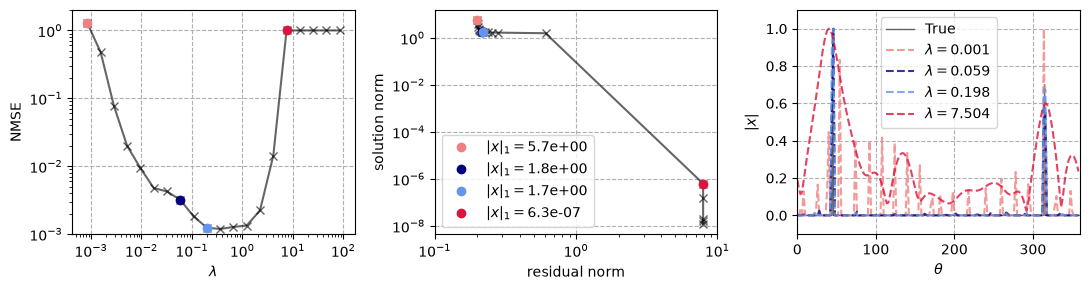

In [43]:
idx2plt = [0, 7, 9, 15]
colors = ['lightcoral', 'navy', 'cornflowerblue', 'crimson']

fig, axs = plt.subplots(1, 3, figsize = (11,3))
axs[0].loglog(lambda_grid, nmse, 'x-k', alpha = 0.6)
axs[0].grid(linestyle = '--')
axs[0].set_xlim((0.5*lambda_grid[0], 2*lambda_grid[-1]))
axs[0].set_ylim((1e-3, 2.0))
axs[0].set_xlabel(r'$\lambda$')
axs[0].set_ylabel(r'NMSE')

axs[1].loglog(res_norms, sol_norms, '-xk', alpha = 0.6)
axs[1].grid(linestyle = '--')
axs[1].set_xlabel(r'residual norm')
axs[1].set_ylabel(r'solution norm')
axs[1].set_xlim((0.1, 10))
#axs[1].set_ylim((1, 10))

axs[2].plot(theta_deg_true, np.abs(x_true)/np.amax(np.abs(x_true)), color ='k', alpha = 0.6, label = "True", linewidth = 1.0)
for i, idx in enumerate(idx2plt):
    axs[0].loglog(lambda_grid[idx], nmse[idx], 'o', color = colors[i])
    axs[1].loglog(res_norms[idx], sol_norms[idx], 'o', color = colors[i], 
                  label = r"$|x|_1 = ${:.1e}".format(np.linalg.norm(x_lasso_list[idx], 1)))
    axs[2].plot(np.rad2deg(theta_dir), np.abs(x_lasso_list[idx])/np.amax(np.abs(x_lasso_list[idx])), 
        '--', color = colors[i], label = r"$\lambda = {:.3f}$".format(lambda_grid[idx]), alpha = 0.8)
axs[1].legend()
axs[2].legend()
axs[2].grid(linestyle = '--')
axs[2].set_xlim((0, 360))
axs[2].set_ylim((-0.1, 1.1))
axs[2].set_xlabel(r'$\theta$')
axs[2].set_ylabel(r'$|x|$')
plt.tight_layout()


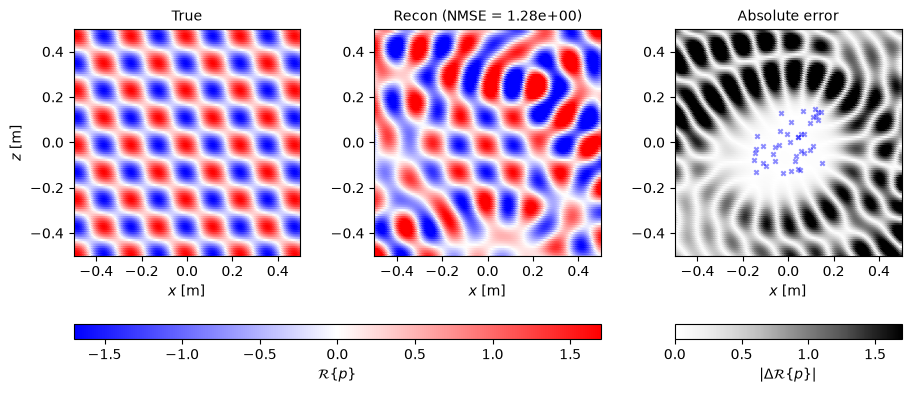

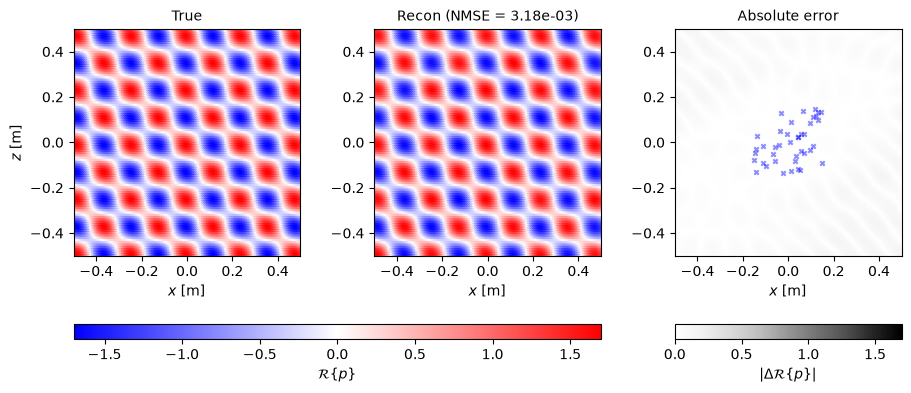

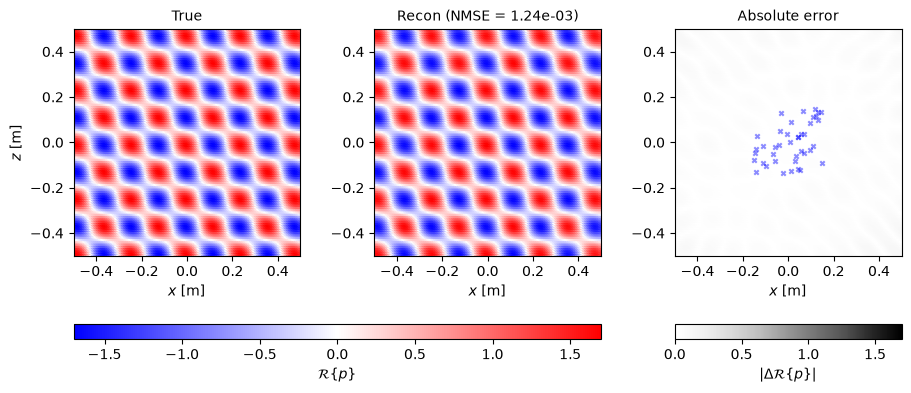

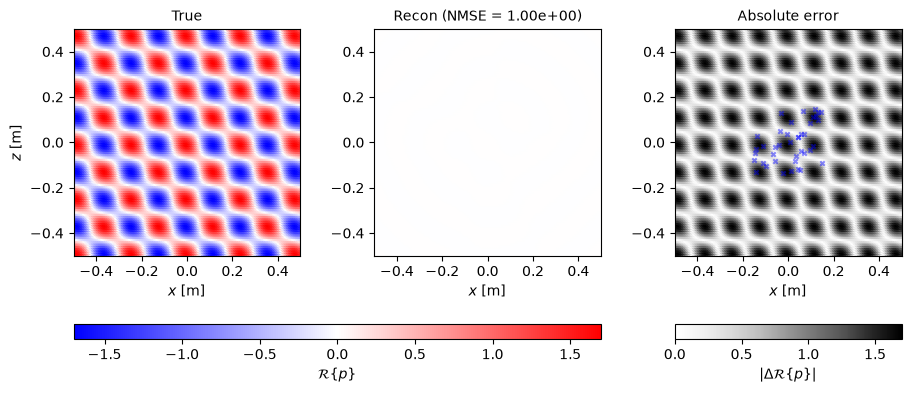

In [44]:
for i in idx2plt:
    pres_recon = Arec @ x_lasso_list[i]
    compare_sf(figsize = (9,4), coord = coord_recon, pres_ref = ref.b_true, pres_recon = pres_recon)    

## 7.4. Discrepancy principle

Let's see how we can build upon the infrastructure of `PyRegTools`. In the module `regchoice`, the `discrep` is tailored for Tikhonov regularization using the SVD of the sensing matrix. Given the simplicity of the discrepancy principle, it is easy to implement a method that solves the LASSO problem, computes the residual norm, and returns:

\begin{equation}
\text{DP}(\lambda) = \|\mathbf{A}\mathbf{x}_{\lambda}-\mathbf{b}\|_2^2 - \|\mathbf{n}\|_2^2
\end{equation}

Then, one can pass it to `scipy.optimize.brentq`. We can see how this works and plot the solution and reconstruction.

In [45]:
def discrep_fun(lam, A, b, noise_norm):
    x_lasso = regsolvers.cvx_reg(A, b, lam, is_lasso = True, is_complex = True)
    res_norm = np.linalg.norm(A @ x_lasso - b)
    return res_norm**2 - noise_norm**2

In [46]:
reg_min = scipy.optimize.brentq(discrep_fun, lambda_grid[0], lambda_grid[-1], args=(problem.A, problem.b_noisy, noise_norm))

In [47]:
x_lasso = regsolvers.cvx_reg(problem.A, problem.b_noisy, reg_min, is_lasso = True, is_complex = True)

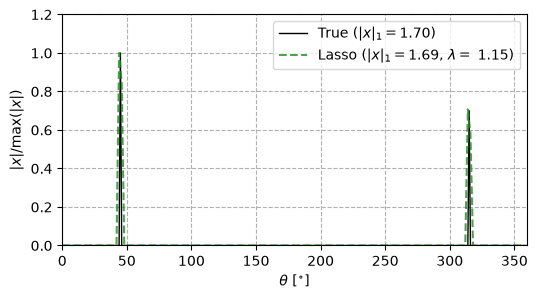

In [48]:
plt.figure(figsize = (6,3))
plt.plot(theta_deg_true, np.abs(x_true)/np.amax(np.abs(x_true)), color ='k', 
         label = r"True ($|x|_1 = ${:.2f})".format(np.linalg.norm(x_true, 1)), linewidth = 1.0)
plt.plot(np.rad2deg(theta_dir), np.abs(x_lasso)/np.amax(np.abs(x_lasso)), 
        '--', color = 'forestgreen',label = r"Lasso ($|x|_1 = ${:.2f}, $\lambda = $ {:.2f})".format(np.linalg.norm(x_lasso, 1), reg_min), alpha = 0.8)
plt.legend(ncols = 1)
plt.grid(linestyle = '--')
plt.xlim((0,360))
plt.ylim((0,1.2))
plt.xlabel(r"$\theta$ [$^{\circ}$]")
plt.ylabel(r"$|x|/\text{max}(|x|)$");

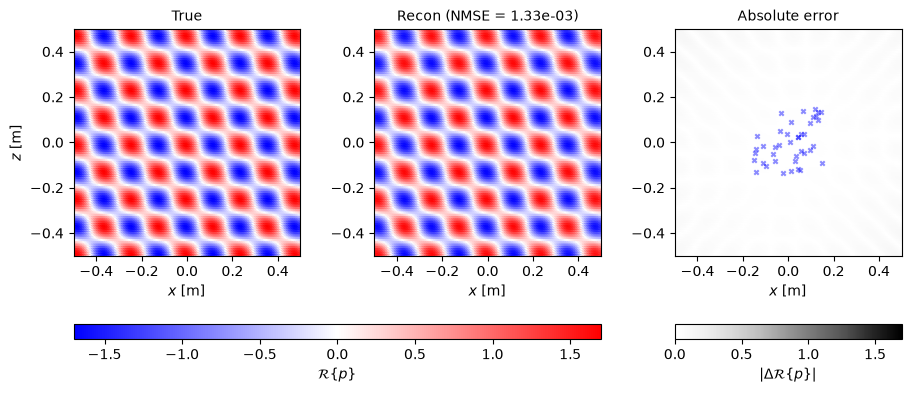

In [49]:
pres_recon = Arec @ x_lasso
compare_sf(figsize = (9,4), coord = coord_recon, pres_ref = ref.b_true, pres_recon = pres_recon) 

## 7.5  When Sparsity Is Not an Appropriate Assumption

So far, we have considered sound fields composed of a small number of dominant plane waves, for which $\ell_1$ regularization is particularly attractive. However, not every sound field admits a sparse representation. As a counterexample, we now consider a **smooth angular distribution of plane waves**, where many propagation directions contribute to the sound field.

We reconstruct this distribution using Lasso regression. Since the $\ell_1$ penalty promotes sparsity, the reconstructed angular spectrum may contain a small number of concentrated peaks rather than reproducing the original smooth distribution. These sparse coefficients may still provide a reasonable approximation of the measured pressure field (or not).

This example highlights an important distinction: **a small reconstruction residual does not necessarily imply accurate recovery of the underlying plane-wave distribution**.

The choice of regularization should therefore reflect the expected physical structure of the solution. While $\ell_1$ regularization is appropriate for fields dominated by a few discrete plane waves, smooth or distributed angular spectra may be better represented using $\ell_2$ regularization or other priors that explicitly promote smoothness.

In [50]:
problem = SoundField2D(c0 = 340, freq = 2000)
problem.set_mic_random_array(x_len = 0.3, z_len = 0.3, m = 40)
factor = 4
problem.smooth_sf(q = factor)
problem.add_noise(snr = snr)
theta_deg_true = np.arange(0, 360, 1)
x_true = (1/len(theta_deg_true))*np.sin(factor * np.deg2rad(theta_deg_true))**2

In [51]:
problem.get_sens_mtx(nwaves = 180)
lambda_max = 2 * np.max(np.abs(problem.A.conj().T @ problem.b_noisy))
reg_min = scipy.optimize.brentq(discrep_fun, lambda_grid[0], lambda_grid[-1], args=(problem.A, problem.b_noisy, noise_norm))
x_lasso = regsolvers.cvx_reg(problem.A, problem.b_noisy, reg_min, is_lasso = True, is_complex = True)

In [52]:
coord_recon = problem.pt_array(x_len = 1.0, z_len = 1.0, n_x = 100, n_z = 100)
k_rec_vec = problem.k0 * np.array([np.sin(theta_dir), np.cos(theta_dir)])
Arec = np.exp(-1j * coord_recon @ k_rec_vec)
pres_recon = Arec @ x_lasso

In [53]:
ref = SoundField2D(c0 = problem.c0, freq = problem.freq) # instantiate
ref.set_mic_array(x_len = coord_recon[:,0].max()-coord_recon[:,0].min(), 
                  z_len = coord_recon[:,1].max()-coord_recon[:,1].min(), 
                  n_x = 100, n_z = 100)
ref.smooth_sf(q = factor)

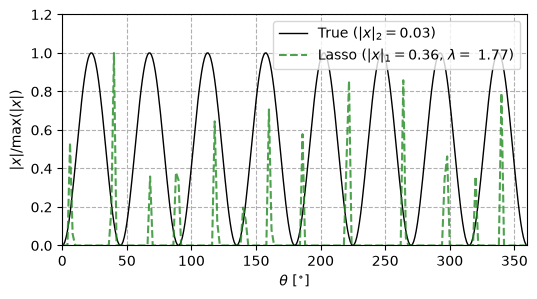

In [54]:
plt.figure(figsize = (6,3))
plt.plot(theta_deg_true, np.abs(x_true)/np.amax(np.abs(x_true)), color ='k', 
         label = r"True ($|x|_2 = ${:.2f})".format(np.linalg.norm(x_true, 2)), linewidth = 1.0)
plt.plot(np.rad2deg(theta_dir), np.abs(x_lasso)/np.amax(np.abs(x_lasso)), 
        '--', color = 'forestgreen',label = r"Lasso ($|x|_1 = ${:.2f}, $\lambda = $ {:.2f})".format(np.linalg.norm(x_lasso, 1), reg_min), alpha = 0.8)
plt.legend(ncols = 1)
plt.grid(linestyle = '--')
plt.xlim((0,360))
plt.ylim((0,1.2))
plt.xlabel(r"$\theta$ [$^{\circ}$]")
plt.ylabel(r"$|x|/\text{max}(|x|)$");

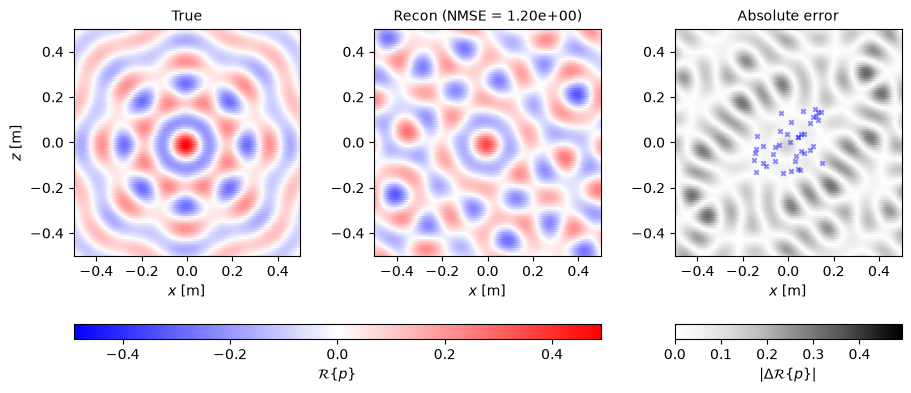

In [55]:
compare_sf(figsize = (9,4), coord = coord_recon, pres_ref = ref.b_true, pres_recon = pres_recon) 

## Conclusions

In this notebook, we explored the reconstruction of a two-dimensional sound field using plane-wave expansion and regularized inverse methods, including sparse reconstruction.

The main conclusions are:

1. **Regularization is essential for ill-posed inverse problems.** When the sensing matrix is underdetermined or ill-conditioned, a direct least-squares solution may be unstable or nonunique. Regularization introduces additional assumptions that help select meaningful solutions.

2. **The choice of regularization reflects prior knowledge about the sound field.** Tikhonov regularization penalizes the squared Euclidean norm of the coefficients and generally produces distributed solutions. In contrast, $\ell_1$ regularization promotes sparse solutions and is particularly appropriate when the sound field can be represented by a small number of dominant plane waves.

3. **The regularization parameter controls the tradeoff between data fitting and sparsity.** In Tikhonov or Lasso regression, small values of $\lambda$ allow a closer fit to the measurements, while larger values suppress more coefficients. Strategies such as the discrepancy principle, L-curve, and cross-validation can help select an appropriate parameter, although no single strategy is universally optimal.

4. **Sparse recovery depends strongly on the sensing matrix.** Mutual coherence measures the similarity between candidate plane-wave responses at the microphone positions. High coherence makes it difficult to distinguish different propagation directions, even when the number of measurements appears sufficient.

5. **Theoretical recovery conditions are useful but often conservative.** Mutual coherence and the Restricted Isometry Property (RIP) provide sufficient conditions for uniqueness and stable sparse recovery. However, these conditions may be difficult to satisfy or verify for physically structured sensing matrices. Their violation does not necessarily imply that reconstruction will fail.

6. **More measurements do not automatically guarantee better sparse recovery.** The microphone arrangement, measurement aperture, frequency, and angular discretization all influence the conditioning and coherence of the sensing matrix. A larger number of microphones is generally beneficial, but their spatial distribution is equally important.

Overall, sparse sound-field reconstruction illustrates how **physical modeling, measurement design, and regularization must be considered together**. Successful recovery requires not only an appropriate optimization algorithm but also a sensing matrix that can distinguish the relevant plane-wave components.

## Appendix: Conceptural figure

This is just used to generate a conceptual figure. 

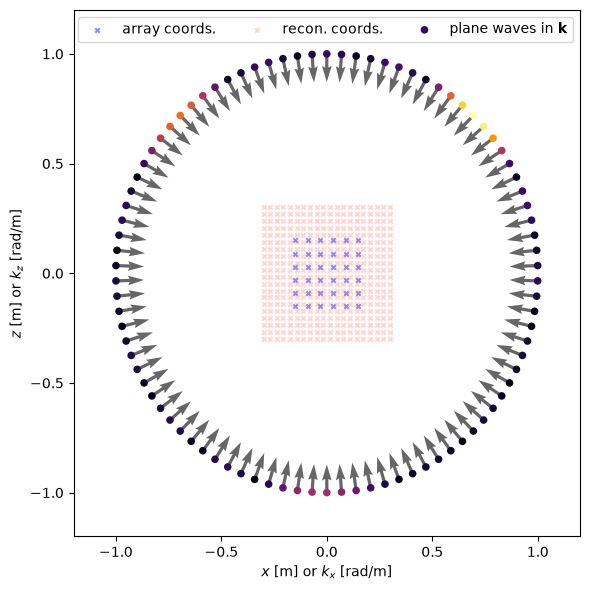

In [56]:
problem.set_mic_array(x_len = 0.6, z_len = 0.6, n_x = 20, n_z = 20)
recon_coord = problem.coord

problem.set_mic_array(x_len = 0.3, z_len = 0.3, n_x = 6, n_z = 6)
#problem.smooth_sf(factor = 3)
problem.compute_pres(theta_deg = (45, 180, 315), amps = (1,0.5,0.7))
problem.add_noise(snr = 30, seed = 0)

problem.get_sens_mtx(nwaves = 90)
u, s, v = regsolvers.csvd(problem.A)

theta_dir = problem.wave_directions()
coords_sol = np.array([np.sin(theta_dir), np.cos(theta_dir)]).T
u_sol = -coords_sol[:,0]
v_sol = -coords_sol[:,1]

lam_l = regchoice.l_curve(u, s, problem.b_noisy, r_min = 1e-8, plotit = False) # evoke reg choice method
x_tik = regsolvers.tikhonov(u, s, v, problem.b_noisy, lam_l) # evoke tikhonov solver passing the optimal reg parameter

plt.figure(figsize = (6,6))
plt.scatter(problem.coord[:, 0], problem.coord[:, 1], c="b", s=10, alpha=0.45, marker="x", label = "array coords.")
plt.scatter(recon_coord[:, 0], recon_coord[:, 1], c="tomato", s=10, alpha=0.25, marker="x", label = "recon. coords.")

plt.quiver(coords_sol[:,0], coords_sol[:,1], u_sol, v_sol, alpha = 0.6)
plt.scatter(coords_sol[:,0], coords_sol[:,1], c=np.abs(x_tik)/np.amax(np.abs(x_tik)), cmap='inferno', s=30, edgecolor='none',
                      vmin = 0, vmax = 1, label = r"plane waves in $\mathbf{k}$")
plt.legend(ncols = 3)
plt.xlabel(r"$x$ [m] or $k_x$ [rad/m]")
plt.ylabel(r"$z$ [m] or $k_z$ [rad/m]")
plt.xlim((-1.2,1.2))
plt.ylim((-1.2,1.2))
plt.tight_layout()
plt.savefig("sf2D_scheme.svg")